In [1]:
from langgraph.graph import MessagesState, START, StateGraph
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

from langchain_groq import ChatGroq
from langchain_core.messages.utils import trim_messages, count_tokens_approximately

In [2]:
load_dotenv()

True

In [3]:
model = ChatGroq(model="openai/gpt-oss-120b")

In [4]:
MAX_TOKENS = 150

In [5]:
def call_model(state: MessagesState):
    
    # Trim conversation history -> last N messages that fit within the token budget
    messages = trim_messages(
        state["messages"],
        strategy="last",                      
        token_counter=count_tokens_approximately,
        max_tokens=MAX_TOKENS
    )

    print('Current Token Count ->', count_tokens_approximately(messages=messages))

    for message in messages:
        print(message.content)

    response = model.invoke(messages)

    return {"messages": [response]}

In [6]:
builder = StateGraph(MessagesState)
builder.add_node("call_model", call_model)
builder.add_edge(START, "call_model")

In [7]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

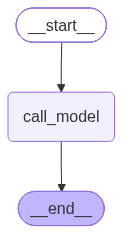

In [8]:
graph

In [9]:
config = {"configurable": {"thread_id": "chat-1"}}

result = graph.invoke(
    {"messages": [{"role": "user", "content": "Hi, my name is Raghav."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 10
Hi, my name is Raghav.


'Hello Raghav! Nice to meet you. How can I assist you today?'

In [10]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "I am learning LangGraph."}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 40
Hi, my name is Raghav.
Hello Raghav! Nice to meet you. How can I assist you today?
I am learning LangGraph.


'That’s great! LangGraph is a powerful way to build composable, multi‑step LLM applications using a graph‑based approach. Here’s a quick starter guide to help you get up and running.\n\n---\n\n## 1️⃣ What is LangGraph?\n\n- **Graph‑oriented**: You define **nodes** (functions, prompts, agents) and **edges** (the flow of data) to create a directed graph that represents the reasoning or workflow.\n- **Stateful**: A shared `State` object travels along the graph, letting each node read/write information.\n- **Composable**: Nodes can be reused across different graphs, making it easy to build modular pipelines.\n- **Iterative & Conditional**: Loops, branches, and conditional routing are first‑class citizens.\n\n---\n\n## 2️⃣ Core Concepts\n\n| Concept | Description |\n|---------|-------------|\n| **Node** | A callable (function, LangChain chain, LLM call, etc.) that receives the current state and returns an updated state (or a subset). |\n| **Edge** | Defines which node runs next. Can be stat

In [11]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "Can you explain short term memory?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 13
Can you explain short term memory?


'**Short‑term memory (STM)** is the brain’s “scratch‑pad” for holding a small amount of information briefly while we use it. It’s one of the core components of the broader memory system, sitting between the immediate, fleeting sensory input and the more durable long‑term memory.\n\n---\n\n## 1. Core Features\n\n| Feature | Typical Description |\n|---------|----------------------|\n| **Capacity** | About **7\u202f±\u202f2 items** (Miller’s classic “magic number”). In practice, we can keep roughly 5–9 discrete chunks of information at once. |\n| **Duration** | Information fades after **15–30\u202fseconds** if not actively rehearsed. |\n| **Encoding** | Primarily **acoustic/phonological** (sound‑based) for most people, though visual and spatial codes are also used. |\n| **Nature of storage** | Holds **temporary, actively maintained** representations. It is not a permanent record; it’s a dynamic workspace. |\n\n---\n\n## 2. How It Works\n\n1. **Encoding from the senses** – When you hear a 

In [12]:
result = graph.invoke(
    {"messages": [{"role": "user", "content": "What is my name?"}]},
    config,
)

result["messages"][-1].content

Current Token Count -> 8
What is my name?


'I don’t know your name. If you’d like to share it, I can use it when we chat!'

In [13]:
for item in graph.get_state({"configurable": {"thread_id": "chat-1"}}).values['messages']:
    print(item.content)
    print('-'*120)

Hi, my name is Raghav.
------------------------------------------------------------------------------------------------------------------------
Hello Raghav! Nice to meet you. How can I assist you today?
------------------------------------------------------------------------------------------------------------------------
I am learning LangGraph.
------------------------------------------------------------------------------------------------------------------------
That’s great! LangGraph is a powerful way to build composable, multi‑step LLM applications using a graph‑based approach. Here’s a quick starter guide to help you get up and running.

---

## 1️⃣ What is LangGraph?

- **Graph‑oriented**: You define **nodes** (functions, prompts, agents) and **edges** (the flow of data) to create a directed graph that represents the reasoning or workflow.
- **Stateful**: A shared `State` object travels along the graph, letting each node read/write information.
- **Composable**: Nodes can be r